# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [1]:
import pandas as pd
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import numpy as np
iris = load_iris(as_frame=True)

- ### Qué representa cada instancia.

Representa las medidas de sepal o petal de una muestra de flor Iris en concreto.

In [2]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [3]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


- ### Número de instancias y características.

150 instancias y 4 características

- ### Nombre y significado de cada característica.

sepal length (cm): Longitud del sépalo (la estructura floral externa que protege al capullo), medida en centímetros.

sepal width (cm): Ancho del sépalo en su punto más amplio, medido en centímetros.

petal length (cm): Longitud del pétalo interior de la flor, medida en centímetros.

petal width (cm): Ancho del pétalo interior de la flor, medido en centímetros.



- ### Clases y cantidad de ejemplos por clase.


In [4]:
print(iris.target.value_counts())

target
0    50
1    50
2    50
Name: count, dtype: int64


3 clases y 50 instancias


- ### Dimensiones de la matriz de características y del vector de etiquetas.

In [5]:
print(iris.data.shape)

(150, 4)


In [6]:
print(iris.data)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  5.1               3.5                1.4               0.2
1                  4.9               3.0                1.4               0.2
2                  4.7               3.2                1.3               0.2
3                  4.6               3.1                1.5               0.2
4                  5.0               3.6                1.4               0.2
..                 ...               ...                ...               ...
145                6.7               3.0                5.2               2.3
146                6.3               2.5                5.0               1.9
147                6.5               3.0                5.2               2.0
148                6.2               3.4                5.4               2.3
149                5.9               3.0                5.1               1.8

[150 rows x 4 columns]


- ### Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [7]:
# Tabla con cinco ejemplos
iris.frame.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


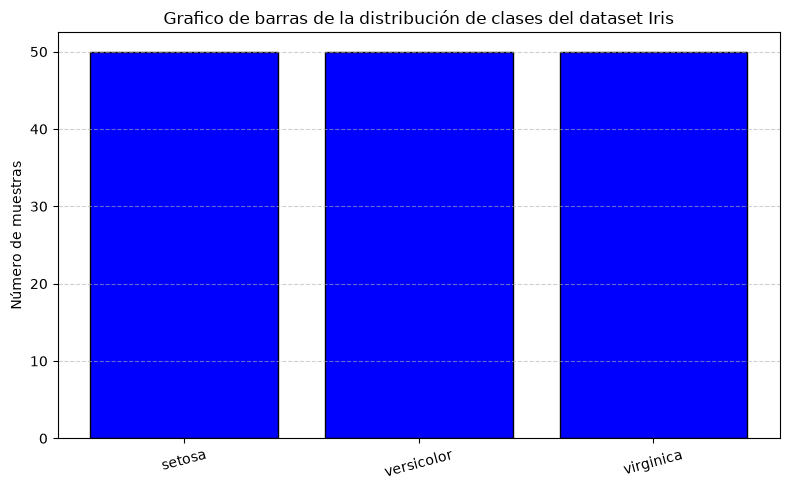

In [8]:
# Gráfico de barras de la distribución de clases 
plt.figure(figsize=(8, 5))
plt.bar(iris.target_names, iris.target.value_counts(), color="blue", edgecolor="black")

plt.title("Grafico de barras de la distribución de clases del dataset Iris")
plt.ylabel("Número de muestras")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

SVM, MLP y Regresión Logística: Sensibles porque calculan distancias geométricas o usan gradientes. Si una variable tiene números más grandes, domina a las demás.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Los modelos lineales como la regresión logística o SVM lineal, ya que solo puede trazar hiperplanos rectos para separar clases.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Porque se desconoce el tipo de frontera ideal para separar las clases. Y por el tiempo computacional que se puede demorar en entrenar el modelo.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.



## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.



In [9]:
# iris.frame.hist(figsize=(10,10))

In [10]:
from sklearn.model_selection import train_test_split

# Dataset con particiones para entrenamiento 70%, validación 15% y prueba 15%
x_aux, x_test, y_aux, y_test = train_test_split(iris.data, iris.target, test_size=0.15, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_aux, y_aux, test_size=0.15, random_state=42)


In [11]:
from sklearn.preprocessing import StandardScaler

# Estandarización de los datos
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [12]:
# Modelo Gaussian Naive Bayes.

from sklearn.naive_bayes import GaussianNB


model_gnb = GaussianNB(var_smoothing=1e-9)
model_gnb.fit(x_train_scaled, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[36.,34.,37.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.34,0.32,0.35]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[-1.01, 0.89,-1.3 ,-1.26], [ 0.13,-0.61, 0.29, 0.18], [ 0.86,-0.31, 1. , 1.06]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.18,0.82,0.01,0.02], [0.4 ,0.43,0.07,0.07], [0.61,0.48,0.09,0.13]]"


In [13]:
# Regresión logística multiclase.


from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=500)
model_lr.fit(x_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [14]:

# SVM lineal.

from sklearn.svm import SVC

model_svm = SVC(kernel="linear", C=1.0, random_state=42)
model_svm.fit(x_train_scaled, y_train)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [15]:
# Árbol de decisión.

from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)
model_dt.fit(x_train_scaled, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [16]:
# Random Forest.

from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
model_rf.fit(x_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [17]:
# Gradient Boosting.

from sklearn.ensemble import GradientBoostingClassifier

model_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
model_gb.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [18]:
# MLP de clasificación.

from sklearn.neural_network import MLPClassifier

model_mlp = MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=1000, random_state=42)
model_mlp.fit(x_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(50,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [19]:
# Predicciones sobre el conjunto de VALIDACIÓN
y_pred_val_gnb = model_gnb.predict(x_val_scaled)
y_pred_val_lr  = model_lr.predict(x_val_scaled)
y_pred_val_svm = model_svm.predict(x_val_scaled)
y_pred_val_dt  = model_dt.predict(x_val_scaled)
y_pred_val_rf  = model_rf.predict(x_val_scaled)
y_pred_val_gb  = model_gb.predict(x_val_scaled)
y_pred_val_mlp = model_mlp.predict(x_val_scaled)

In [20]:
# Accuracy y F1-score en Validación
from sklearn.metrics import accuracy_score, f1_score
acc_val_gnb = accuracy_score(y_val, y_pred_val_gnb)
f1_val_gnb = f1_score(y_val, y_pred_val_gnb, average='macro')
acc_val_lr  = accuracy_score(y_val, y_pred_val_lr)
f1_val_lr  = f1_score(y_val, y_pred_val_lr, average='macro')
acc_val_svm = accuracy_score(y_val, y_pred_val_svm)
f1_val_svm = f1_score(y_val, y_pred_val_svm, average='macro')
acc_val_dt  = accuracy_score(y_val, y_pred_val_dt)
f1_val_dt  = f1_score(y_val, y_pred_val_dt, average='macro')
acc_val_rf  = accuracy_score(y_val, y_pred_val_rf)
f1_val_rf  = f1_score(y_val, y_pred_val_rf, average='macro')
acc_val_gb  = accuracy_score(y_val, y_pred_val_gb)
f1_val_gb  = f1_score(y_val, y_pred_val_gb, average='macro')
acc_val_mlp = accuracy_score(y_val, y_pred_val_mlp)
f1_val_mlp = f1_score(y_val, y_pred_val_mlp, average='macro')
print("Accuracy y F1-score en Validación:")
print(f"Gaussian Naive Bayes: \nAcc:{acc_val_gnb} \nF1: {f1_val_gnb}")
print(f"Logistic Regression: \nAcc:{acc_val_lr} \nF1: {f1_val_lr}")
print(f"SVM: \nAcc:{acc_val_svm} \nF1: {f1_val_svm}")
print(f"Decision Tree: \nAcc:{acc_val_dt} \nF1: {f1_val_dt}")
print(f"Random Forest: \nAcc:{acc_val_rf} \nF1: {f1_val_rf}")
print(f"Gradient Boosting: \nAcc:{acc_val_gb} \nF1: {f1_val_gb}")
print(f"MLP: \nAcc:{acc_val_mlp} \nF1: {f1_val_mlp}")

Accuracy y F1-score en Validación:
Gaussian Naive Bayes: 
Acc:1.0 
F1: 1.0
Logistic Regression: 
Acc:0.95 
F1: 0.9521367521367522
SVM: 
Acc:0.95 
F1: 0.9521367521367522
Decision Tree: 
Acc:0.95 
F1: 0.9521367521367522
Random Forest: 
Acc:1.0 
F1: 1.0
Gradient Boosting: 
Acc:1.0 
F1: 1.0
MLP: 
Acc:0.95 
F1: 0.9521367521367522


In [21]:
# Naive Bayes prueba
y_pred_gnb_test = model_gnb.predict(x_test_scaled)
# Regression logística multiclase prueba
y_pred_lr_test = model_lr.predict(x_test_scaled)
# SVM lineal prueba
y_pred_svm_test = model_svm.predict(x_test_scaled)
# Árbol de decisión prueba
y_pred_dt_test = model_dt.predict(x_test_scaled)
# Random Forest prueba
y_pred_rf_test = model_rf.predict(x_test_scaled)
# Gradient Boosting prueba
y_pred_gb_test = model_gb.predict(x_test_scaled)
# MLP de clasificación prueba
y_pred_mlp_test = model_mlp.predict(x_test_scaled)

In [22]:
# Accuracy y F1-score en Prueba
acc_gnb_test = accuracy_score(y_test, y_pred_gnb_test)
f1_gnb_test = f1_score(y_test, y_pred_gnb_test, average='macro')
acc_lr_test = accuracy_score(y_test, y_pred_lr_test)
f1_lr_test = f1_score(y_test, y_pred_lr_test, average='macro')
acc_svm_test = accuracy_score(y_test, y_pred_svm_test)
f1_svm_test = f1_score(y_test, y_pred_svm_test, average='macro')
acc_dt_test = accuracy_score(y_test, y_pred_dt_test)
f1_dt_test = f1_score(y_test, y_pred_dt_test, average='macro')
acc_rf_test = accuracy_score(y_test, y_pred_rf_test)
f1_rf_test = f1_score(y_test, y_pred_rf_test, average='macro')
acc_gb_test = accuracy_score(y_test, y_pred_gb_test)
f1_gb_test = f1_score(y_test, y_pred_gb_test, average='macro')
acc_mlp_test = accuracy_score(y_test, y_pred_mlp_test)
f1_mlp_test = f1_score(y_test, y_pred_mlp_test, average='macro')
print("Accuracy y F1-score en Prueba:")
print(f"Gaussian Naive Bayes: \nAcc:{acc_gnb_test} \nF1: {f1_gnb_test}")
print(f"Logistic Regression: \nAcc:{acc_lr_test} \nF1: {f1_lr_test}")
print(f"SVM: \nAcc:{acc_svm_test} \nF1: {f1_svm_test}")
print(f"Decision Tree: \nAcc:{acc_dt_test} \nF1: {f1_dt_test}")
print(f"Random Forest: \nAcc:{acc_rf_test} \nF1: {f1_rf_test}")
print(f"Gradient Boosting: \nAcc:{acc_gb_test} \nF1: {f1_gb_test}")
print(f"MLP: \nAcc:{acc_mlp_test} \nF1: {f1_mlp_test}")

Accuracy y F1-score en Prueba:
Gaussian Naive Bayes: 
Acc:1.0 
F1: 1.0
Logistic Regression: 
Acc:1.0 
F1: 1.0
SVM: 
Acc:0.9565217391304348 
F1: 0.9547511312217195
Decision Tree: 
Acc:0.9565217391304348 
F1: 0.9547511312217195
Random Forest: 
Acc:1.0 
F1: 1.0
Gradient Boosting: 
Acc:1.0 
F1: 1.0
MLP: 
Acc:0.9565217391304348 
F1: 0.9547511312217195


In [23]:
# Matriz de confusión para Naive Bayes
from sklearn.metrics import confusion_matrix
cm_nb = confusion_matrix(y_test, y_pred_gnb_test)
cm_svm = confusion_matrix(y_test, y_pred_svm_test)
cm_mlp = confusion_matrix(y_test, y_pred_mlp_test)

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.



In [24]:
print("-"*180)
print("Modelo\t\t\tTransformación\t\tHiperparámetros principales\t\t\t\t\t\t\tAccuracy de prueba\tF1 Macro de prueba")
print("-"*180)

print(f"Gaussian Naive Bayes\t StandardScaler\t\tvar_smoothing=1e-9\t\t\t\t\t\t\t\t{acc_gnb_test:.4f}\t\t\t{f1_gnb_test:.4f}")

print(f"Logistic Regression\t StandardScaler\t\tsolver='lbfgs', max_iter=1000\t\t\t\t\t\t\t{acc_lr_test:.4f}\t\t\t{f1_lr_test:.4f}")

print(f"SVM\t\t\t StandardScaler\t\tkernel='linear', C=1.0, random_state=42\t\t\t\t\t\t{acc_svm_test:.4f}\t\t\t{f1_svm_test:.4f}")

print(f"Decision Tree\t\t StandardScaler\t\tmax_depth=3, criterion='gini', random_state=42\t\t\t\t\t{acc_dt_test:.4f}\t\t\t{f1_dt_test:.4f}")

print(f"Random Forest\t\t StandardScaler\t\tn_estimators=100, max_depth=3, random_state=42\t\t\t\t\t{acc_rf_test:.4f}\t\t\t{f1_rf_test:.4f}")

print(f"Gradient Boosting\t StandardScaler\t\tn_estimators=100, learning_rate=0.1, random_state=42\t\t\t\t{acc_gb_test:.4f}\t\t\t{f1_gb_test:.4f}")

print(f"MLP\t\t\t StandardScaler\t\thidden_layer_sizes=(50,), activation='relu', max_iter=1000, random_state=42\t{acc_mlp_test:.4f}\t\t\t{f1_mlp_test:.4f}")

print("-"*180)

print("Matriz de confusión para Naive Bayes:")
print(cm_nb)

print("Matriz de confusión para SVM:")
print(cm_svm)

print("Matriz de confusión para MLP:")
print(cm_mlp)

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Modelo			Transformación		Hiperparámetros principales							Accuracy de prueba	F1 Macro de prueba
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Gaussian Naive Bayes	 StandardScaler		var_smoothing=1e-9								1.0000			1.0000
Logistic Regression	 StandardScaler		solver='lbfgs', max_iter=1000							1.0000			1.0000
SVM			 StandardScaler		kernel='linear', C=1.0, random_state=42						0.9565			0.9548
Decision Tree		 StandardScaler		max_depth=3, criterion='gini', random_state=42					0.9565			0.9548
Random Forest		 StandardScaler		n_estimators=100, max_depth=3, random_state=42					1.0000			1.0000
Gradient Boosting	 StandardScaler		n_estimators=100, learning_rate=0.1, random_state=42			

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?

Hubo un empate entre cuatro modelos:Gaussian Naive Bayes, Regresión Logística multiclase, Random Forest y Gradient Boosting (Accuracy = 1.0000 y F1 macro = 1.0000). Pero entre ellos, Gaussian Naive Bayes y la Regresión Logística son mejores por que alcanzan el 100% de precisión siendo modelos mucho más rápidos y computacionalmente más ligeros que los otros modelos basados en árboles.

2. ¿Cuál fue el modelo más sencillo de programar?

Gaussian Naive Bayes porque no requiere fijar semillas aleatorias "random_state" porque su ajuste es analítico y determinista (calcula directamente la media y varianza de cada clase). Prácticamente no se necesita ajustar los hiperparámetros ,el parámetro var_smoothing funciona bien con su valor por defecto.

3. ¿Accuracy y F1 macro cuentan la misma historia?

No el *Accuracy* mide el porcentaje de predicciones correctas realizadas por el modelo sobre el total de muestras evaluadas, sin distinguir entre las distintas clases.

*F1 Macro* calcula el valor F1 para cada clase de forma independiente y luego obtiene el promedio de todos los F1, dando la misma importancia a todas las clase.

4. ¿Cuál es la diferencia entre las métricas macro y micro?

Macro: Calcula las métricas de manera individual para cada clase y luego promedia los resultados sin ponderar. Dando la misma importancia a todas las clases.

Micro: Primero suma todos los aciertos y errores de todas las clases y luego calcula la una unica métrica global. Haciendo que las clases con mayor muestra tengan más influencia.

5. ¿Qué aporta el MLP frente a un modelo lineal?

Un modelo lineal como la regresión logística o SVM lineal, solo puede trazar hiperplanos rectos para separar clases. El MLP, gracias a sus capas ocultas y funciones de activación no lineales (como relu), puede modelar curvaturas y regiones de decisión arbitrariamente más complejas. Pero en este caso no presenta ninguna ventaja por el dataset iris es linealmente separable.

#####  **Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.**

Lo que Sí se puede concluir es que las flores están en la frontera. Las muestras 68 y 76 son flores versicolor atípicamente grandes. Como sus medidas caen en la zona donde versicolor y virginica se cruzan, el modelo las confunde fácilmente.   
La setosa no tiene este problema ya que la clase setosa tiene pétalos mucho más pequeños (alrededor de $1.46\text{ cm}$), por lo que nunca se confunde con ninguna de las otras dos.

Lo que NO se puede concluir es si el modelo no está roto ni mal programado: Fallar 1 o 2 flores de un grupo de prueba tan pequeño no significa que el algoritmo sirva poco, sino que los datos tienen un límite biológico natural donde las especies se parecen.Cambiar los parámetros no garantiza corregirlo. No se puede asegurar que modificando los hiperparámetros arregle este error sin desacomodar la clasificación de otras flores que ya estaban bien predichas.



In [25]:
print(y_test[y_test != y_pred_svm_test])
print(y_test[y_test != y_pred_dt_test])

68    1
Name: target, dtype: int64
76    1
Name: target, dtype: int64


In [26]:
print(iris.frame.loc[68])
print(iris.frame.loc[76])
print(iris.frame.groupby('target').mean())

sepal length (cm)    6.2
sepal width (cm)     2.2
petal length (cm)    4.5
petal width (cm)     1.5
target               1.0
Name: 68, dtype: float64
sepal length (cm)    6.8
sepal width (cm)     2.8
petal length (cm)    4.8
petal width (cm)     1.4
target               1.0
Name: 76, dtype: float64
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
target                                                           
0                   5.006             3.428              1.462   
1                   5.936             2.770              4.260   
2                   6.588             2.974              5.552   

        petal width (cm)  
target                    
0                  0.246  
1                  1.326  
2                  2.026  


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

In [27]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)

print(diabetes.frame.head())


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [28]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

#### **Describe qué representa el objetivo numérico y qué variables contiene el dataset.**

El target es la medida de progresión de la enfermedad un año después del inicio del estudio.

Las variables que contiene el dataset son:
- edad: edad en años
- sexo
- imc: índice de masa corporal
- pa: presión arterial promedio
- s1 tc: colesterol total en suero
- s2 ldl: lipoproteínas de baja densidad
- s3 hdl: lipoproteínas de alta densidad
- s4 tch: colesterol total / HDL
- s5 ltg: posiblemente logaritmo del nivel de triglicéridos en suero
- s6 glu: nivel de azúcar en la sangre

#### **Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.**

Según la descripción cada una de las 10 variables de características se ha centrado en la media y escalado por la desviación estándar multiplicada por la raíz cuadrada de n_samples

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No. Un modelo más flexible no siempre produce un menor error en datos nuevos debido al riesgo de sobreajuste (overfitting). Al tener tanta capacidad de adaptación, el modelo tiende a memorizar el ruido y los detalles exactos de los datos de entrenamiento en lugar de aprender la tendencia general. Como resultado, pierde su capacidad de generalizar y comete errores cuando se evalúa con datos que nunca antes ha visto, por lo que a algunas veces un modelo más simple y restringido funciona mejor.


## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.



## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.



In [29]:
x_aux, x_test_diabetes, y_aux, y_test_diabetes = train_test_split(diabetes.data, diabetes.target, test_size=0.15, random_state=42)
x_train_diabetes, x_val_diabetes, y_train_diabetes, y_val_diabetes = train_test_split(x_aux, y_aux, test_size=0.15, random_state=42)

In [30]:
from sklearn.pipeline import make_pipeline

In [31]:
# Modelo Regresión Lineal
from sklearn.linear_model import LinearRegression
model_lr_diabetes = make_pipeline(StandardScaler(),LinearRegression())
model_lr_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [32]:
# MAE ,RSME y R2
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

In [33]:
# Predicciones sobre el conjunto de VALIDACIÓN
y_pred_val_lr_diabetes = model_lr_diabetes.predict(x_val_diabetes)
# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2
    
mae_lr_diabetes, rmse_lr_diabetes, r2_lr_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_lr_diabetes)

print(f"MAE: {mae_lr_diabetes}, R2: {r2_lr_diabetes}, RMSE: {rmse_lr_diabetes}")

MAE: 40.60869783953823, R2: 0.5508555731046324, RMSE: 51.09631921312076


In [34]:
y_pred_test_lr_diabetes = model_lr_diabetes.predict(x_test_diabetes)
mae_lr_test_diabetes, rmse_lr_test_diabetes, r2_lr_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_lr_diabetes)
print(f"MAE: {mae_lr_test_diabetes}, R2: {r2_lr_test_diabetes}, RMSE: {rmse_lr_test_diabetes}")

MAE: 44.80634874846412, R2: 0.41438172151962427, RMSE: 56.560739046825475


In [35]:
# Modelo Ridge
from sklearn.linear_model import Ridge
model_ridge_diabetes = make_pipeline(StandardScaler(),Ridge(alpha=0.5, random_state=42))
model_ridge_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [36]:
y_pred_val_ridge_diabetes = model_ridge_diabetes.predict(x_val_diabetes)

# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
mae_ridge_diabetes, rmse_ridge_diabetes, r2_ridge_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_ridge_diabetes)

print(f"MAE: {mae_ridge_diabetes}, R2: {r2_ridge_diabetes}, RMSE: {rmse_ridge_diabetes}")

MAE: 40.40056355036432, R2: 0.5533096366739827, RMSE: 50.95653637166804


In [37]:
y_pred_test_ridge_diabetes = model_ridge_diabetes.predict(x_test_diabetes)

mae_ridge_test_diabetes, rmse_ridge_test_diabetes, r2_ridge_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_ridge_diabetes)
print(f"MAE: {mae_ridge_test_diabetes}, R2: {r2_ridge_test_diabetes}, RMSE: {rmse_ridge_test_diabetes}")

MAE: 44.816814288002455, R2: 0.4156752176681431, RMSE: 56.49823968120304


In [38]:
# Modelo Lasso
from sklearn.linear_model import Lasso
model_lasso_diabetes = make_pipeline(StandardScaler(),Lasso(random_state=42))
model_lasso_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [39]:
y_pred_val_lasso_diabetes = model_lasso_diabetes.predict(x_val_diabetes)

mae_lasso_diabetes, rmse_lasso_diabetes, r2_lasso_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_lasso_diabetes)    
print(f"MAE: {mae_lasso_diabetes}, R2: {r2_lasso_diabetes}, RMSE: {rmse_lasso_diabetes}")

MAE: 41.268555384514066, R2: 0.5431183413285705, RMSE: 51.534547922580764


In [40]:
y_pred_test_lasso_diabetes = model_lasso_diabetes.predict(x_test_diabetes)
mae_lasso_test_diabetes, rmse_lasso_test_diabetes, r2_lasso_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_lasso_diabetes)
print(f"MAE: {mae_lasso_test_diabetes}, R2: {r2_lasso_test_diabetes}, RMSE: {rmse_lasso_test_diabetes}")

MAE: 44.570517576428294, R2: 0.43321047475294905, RMSE: 55.644042220811926


In [41]:
# Modelo KNN de regresión

from sklearn.neighbors import KNeighborsRegressor

model_knn_diabetes = make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=15))
model_knn_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [42]:
y_pred_val_knn_diabetes = model_knn_diabetes.predict(x_val_diabetes)
mae_knn_diabetes, rmse_knn_diabetes, r2_knn_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_knn_diabetes)
print(f"MAE: {mae_knn_diabetes}, R2: {r2_knn_diabetes}, RMSE: {rmse_knn_diabetes}")

MAE: 45.59181286549708, R2: 0.43203366830935386, RMSE: 57.458979011168026


In [43]:
y_pred_test_knn_diabetes = model_knn_diabetes.predict(x_test_diabetes)
mae_knn_test_diabetes, rmse_knn_test_diabetes, r2_knn_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_knn_diabetes)
print(f"MAE: {mae_knn_test_diabetes}, R2: {r2_knn_test_diabetes}, RMSE: {rmse_knn_test_diabetes}")

MAE: 45.66865671641792, R2: 0.4254286364908869, RMSE: 56.02472742386829


In [44]:
# Modelo Árbol de regresíon
from sklearn.tree import DecisionTreeRegressor

model_dt_diabetes = DecisionTreeRegressor(max_depth=3, random_state=42)
model_dt_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [45]:
y_pred_val_dt_diabetes = model_dt_diabetes.predict(x_val_diabetes)
# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
mae_dt_diabetes, rmse_dt_diabetes, r2_dt_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_dt_diabetes)
print(f"MAE: {mae_dt_diabetes}, R2: {r2_dt_diabetes}, RMSE: {rmse_dt_diabetes}")

MAE: 48.619899291641794, R2: 0.3415899883779223, RMSE: 61.8649721465529


In [46]:
y_pred_test_dt_diabetes = model_dt_diabetes.predict(x_test_diabetes)
mae_dt_test_diabetes, rmse_dt_test_diabetes, r2_dt_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_dt_diabetes)
print(f"MAE: {mae_dt_test_diabetes}, R2: {r2_dt_test_diabetes}, RMSE: {rmse_dt_test_diabetes}")

MAE: 47.594396158287815, R2: 0.34272457683771185, RMSE: 59.9213322266425


In [47]:
# Modelo Random Forest de regresión.
from sklearn.ensemble import RandomForestRegressor
model_rf_diabetes = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
model_rf_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [48]:
y_pred_val_rf_diabetes = model_rf_diabetes.predict(x_val_diabetes)
# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
mae_rf_diabetes, rmse_rf_diabetes, r2_rf_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_rf_diabetes)
print(f"MAE: {mae_rf_diabetes}, R2: {r2_rf_diabetes}, RMSE: {rmse_rf_diabetes}")

MAE: 46.955854954186705, R2: 0.41796177458252526, RMSE: 58.16642372465195


In [49]:
y_pred_test_rf_diabetes = model_rf_diabetes.predict(x_test_diabetes)
mae_rf_test_diabetes, rmse_rf_test_diabetes, r2_rf_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_rf_diabetes)
print(f"MAE: {mae_rf_test_diabetes}, R2: {r2_rf_test_diabetes}, RMSE: {rmse_rf_test_diabetes}")

MAE: 45.13623279226739, R2: 0.43155826053519974, RMSE: 55.72508551102787


In [50]:
# Modelo Gradient Boosting de regresión.
from sklearn.ensemble import GradientBoostingRegressor
model_gb_diabetes = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)
model_gb_diabetes.fit(x_train_diabetes, y_train_diabetes)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

In [51]:
y_pred_val_gb_diabetes = model_gb_diabetes.predict(x_val_diabetes)
# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
mae_gb_diabetes, rmse_gb_diabetes, r2_gb_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_gb_diabetes)
print(f"MAE: {mae_gb_diabetes}, R2: {r2_gb_diabetes}, RMSE: {rmse_gb_diabetes}")

MAE: 44.81521839913741, R2: 0.47260850422549017, RMSE: 55.36855250720629


In [52]:
y_pred_test_gb_diabetes = model_gb_diabetes.predict(x_test_diabetes)
mae_gb_test_diabetes, rmse_gb_test_diabetes, r2_gb_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_gb_diabetes)
print(f"MAE: {mae_gb_test_diabetes}, R2: {r2_gb_test_diabetes}, RMSE: {rmse_gb_test_diabetes}")

MAE: 44.023134287889626, R2: 0.4548737999462581, RMSE: 54.570293750669606


In [53]:
# Modelo MLP de regresión.
from sklearn.neural_network import MLPRegressor
model_mlp_diabetes = make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(100,), max_iter=1000, random_state=42))
model_mlp_diabetes.fit(x_train_diabetes, y_train_diabetes)

d:\David\7Semestre\Recuperación Información\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [54]:
y_pred_val_mlp_diabetes = model_mlp_diabetes.predict(x_val_diabetes)
# MAE ,RSME y R2 (Mean Absolute Error)(Root Mean Squared Error)()
mae_mlp_diabetes, rmse_mlp_diabetes, r2_mlp_diabetes = calculate_metrics(y_val_diabetes, y_pred_val_mlp_diabetes)
print(f"MAE: {mae_mlp_diabetes}, R2: {r2_mlp_diabetes}, RMSE: {rmse_mlp_diabetes}")

MAE: 39.63050565925781, R2: 0.5395119099839951, RMSE: 51.737544124135404


In [55]:
y_pred_test_mlp_diabetes = model_mlp_diabetes.predict(x_test_diabetes)
mae_mlp_test_diabetes, rmse_mlp_test_diabetes, r2_mlp_test_diabetes = calculate_metrics(y_test_diabetes, y_pred_test_mlp_diabetes)
print(f"MAE: {mae_mlp_test_diabetes}, R2: {r2_mlp_test_diabetes}, RMSE: {rmse_mlp_test_diabetes}")

MAE: 45.191807305261555, R2: 0.4207032657209302, RMSE: 56.25463404764847


In [56]:
print("-"*100)
print("Modelo \t\t\t\t\tMAE \t\tRSME \t\tR2")
print("-"*100)
print(f"LinearRegression \t\t\t{mae_lr_test_diabetes:.8f} \t{rmse_lr_test_diabetes:.8f} \t{r2_lr_test_diabetes:.8f}")
print(f"Ridge \t\t\t\t\t{mae_ridge_test_diabetes:.8f} \t{rmse_ridge_test_diabetes:.8f} \t{r2_ridge_test_diabetes:.8f}")
print(f"Lasso \t\t\t\t\t{mae_lasso_test_diabetes:.8f} \t{rmse_lasso_test_diabetes:.8f} \t{r2_lasso_test_diabetes:.8f}")
print(f"kNN de regresión \t\t\t{mae_knn_test_diabetes:.8f} \t{rmse_knn_test_diabetes:.8f} \t{r2_knn_test_diabetes:.8f}")
print(f"Árbol de regresión \t\t\t{mae_dt_test_diabetes:.8f} \t{rmse_dt_test_diabetes:.8f} \t{r2_dt_test_diabetes:.8f}")
print(f"Random Forest de regresión \t\t{mae_rf_test_diabetes:.8f} \t{rmse_rf_test_diabetes:.8f} \t{r2_rf_test_diabetes:.8f}")
print(f"Gradient Boosting de regresión \t\t{mae_gb_test_diabetes:.8f} \t{rmse_gb_test_diabetes:.8f} \t{r2_gb_test_diabetes:.8f}")
print(f"MLP de regresión\t\t\t{mae_mlp_test_diabetes:.8f} \t{rmse_mlp_test_diabetes:.8f} \t{r2_mlp_test_diabetes:.8f}")
print("-"*100)

----------------------------------------------------------------------------------------------------
Modelo 					MAE 		RSME 		R2
----------------------------------------------------------------------------------------------------
LinearRegression 			44.80634875 	56.56073905 	0.41438172
Ridge 					44.81681429 	56.49823968 	0.41567522
Lasso 					44.57051758 	55.64404222 	0.43321047
kNN de regresión 			45.66865672 	56.02472742 	0.42542864
Árbol de regresión 			47.59439616 	59.92133223 	0.34272458
Random Forest de regresión 		45.13623279 	55.72508551 	0.43155826
Gradient Boosting de regresión 		44.02313429 	54.57029375 	0.45487380
MLP de regresión			45.19180731 	56.25463405 	0.42070327
----------------------------------------------------------------------------------------------------


### **Para regresión lineal y MLP, incluye:**

- ### Gráfico de valores reales frente a predicciones.
- ### Gráfico de residuos.


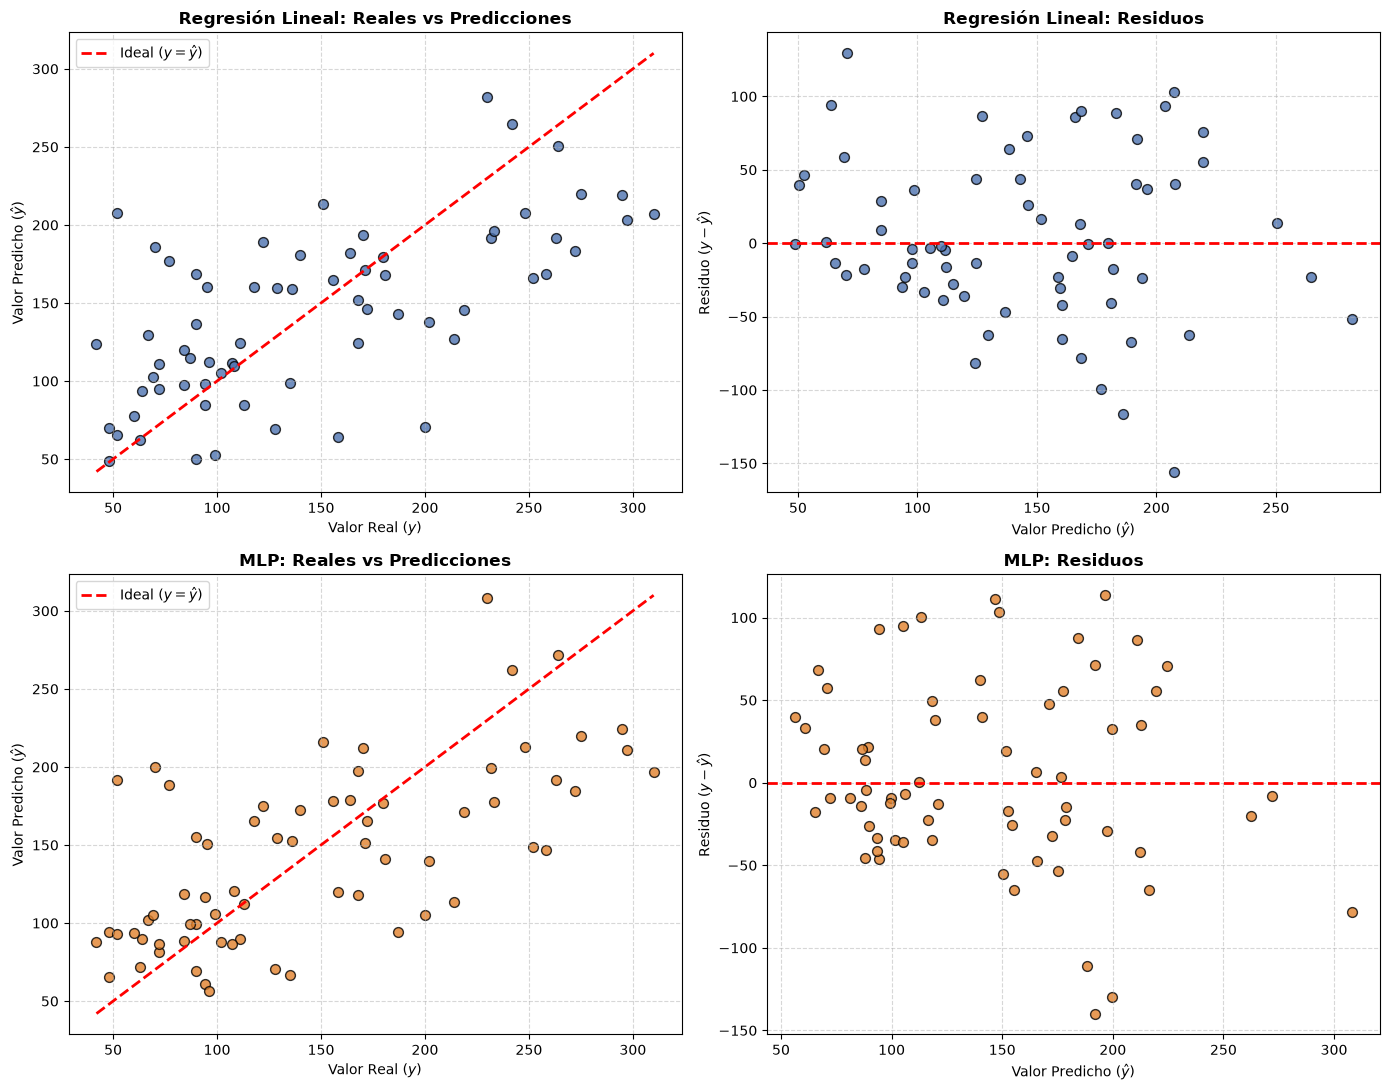

In [57]:

residuos_lr = y_test_diabetes - y_pred_test_lr_diabetes
residuos_mlp = y_test_diabetes - y_pred_test_mlp_diabetes

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

min_val = min(y_test_diabetes.min(), min(y_pred_test_lr_diabetes.min(), y_pred_test_mlp_diabetes.min()))
max_val = max(y_test_diabetes.max(), max(y_pred_test_lr_diabetes.max(), y_pred_test_mlp_diabetes.max()))

# --- Fila 1: Regresión Lineal ---
# Gráfico 1: Reales vs Predicciones (LR)
axes[0, 0].scatter(
    y_test_diabetes, y_pred_test_lr_diabetes, color="#4C72B0", edgecolor="black", alpha=0.8, s=50
)
axes[0, 0].plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2,
    label="Ideal ($y = \\hat{y}$)",
)
axes[0, 0].set_title(
    "Regresión Lineal: Reales vs Predicciones", fontsize=12, fontweight="bold"
)
axes[0, 0].set_xlabel("Valor Real ($y$)", fontsize=10)
axes[0, 0].set_ylabel("Valor Predicho ($\\hat{y}$)", fontsize=10)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
axes[0, 0].legend()

# Gráfico 2: Residuos (LR)
axes[0, 1].scatter(
    y_pred_test_lr_diabetes, residuos_lr, color="#4C72B0", edgecolor="black", alpha=0.8, s=50
)
axes[0, 1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[0, 1].set_title(
    "Regresión Lineal: Residuos", fontsize=12, fontweight="bold"
)
axes[0, 1].set_xlabel("Valor Predicho ($\\hat{y}$)", fontsize=10)
axes[0, 1].set_ylabel("Residuo ($y - \\hat{y}$)", fontsize=10)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# --- Fila 2: MLP ---
# Gráfico 3: Reales vs Predicciones (MLP)
axes[1, 0].scatter(
    y_test_diabetes, y_pred_test_mlp_diabetes, color="#E1812C", edgecolor="black", alpha=0.8, s=50
)
axes[1, 0].plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2,
    label="Ideal ($y = \\hat{y}$)",
)
axes[1, 0].set_title(
    "MLP: Reales vs Predicciones", fontsize=12, fontweight="bold"
)
axes[1, 0].set_xlabel("Valor Real ($y$)", fontsize=10)
axes[1, 0].set_ylabel("Valor Predicho ($\\hat{y}$)", fontsize=10)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)
axes[1, 0].legend()

# Gráfico 4: Residuos (MLP)
axes[1, 1].scatter(
    y_pred_test_mlp_diabetes,
    residuos_mlp,
    color="#E1812C",
    edgecolor="black",
    alpha=0.8,
    s=50,
)
axes[1, 1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1, 1].set_title("MLP: Residuos", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Valor Predicho ($\\hat{y}$)", fontsize=10)
axes[1, 1].set_ylabel("Residuo ($y - \\hat{y}$)", fontsize=10)
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

- ### Dos ejemplos con errores absolutos grandes.

In [58]:
# Errores absolutos grandes
# Errores para Regresión Lineal
df_err_lr = pd.DataFrame(
    {
        "Real": y_test_diabetes,
        "Predicho": y_pred_test_lr_diabetes,
        "Error Absoluto": np.abs(residuos_lr),
    }
).sort_values(by="Error Absoluto", ascending=False)

print("DOS PEORES ERRORES: REGRESIÓN LINEAL")
print(df_err_lr.head(2))

# Errores para MLP
df_err_mlp = pd.DataFrame(
    {
        "Real": y_test_diabetes,
        "Predicho": y_pred_test_mlp_diabetes,
        "Error Absoluto": np.abs(residuos_mlp),
    }
).sort_values(by="Error Absoluto", ascending=False)

print("\nDOS PEORES ERRORES: MLP")
print(df_err_mlp.head(2))

DOS PEORES ERRORES: REGRESIÓN LINEAL
     Real    Predicho  Error Absoluto
56   52.0  207.557355      155.557355
77  200.0   70.612094      129.387906

DOS PEORES ERRORES: MLP
     Real    Predicho  Error Absoluto
56   52.0  191.811496      139.811496
211  70.0  199.818221      129.818221


## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.



In [59]:
# Valores de regularización a probar
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]

resultados_ridge = []
resultados_lasso = []

for a in alphas:
    # --- RIDGE ---
    ridge = Ridge(alpha=a, random_state=42)
    ridge.fit(x_train_diabetes, y_train_diabetes)
    norma_ridge = np.linalg.norm(ridge.coef_)
    rmse_train_ridge = root_mean_squared_error(y_train_diabetes, ridge.predict(x_train_diabetes))
    rmse_val_ridge = root_mean_squared_error(y_val_diabetes, ridge.predict(x_val_diabetes))
    
    resultados_ridge.append([a, norma_ridge, rmse_train_ridge, rmse_val_ridge])
    
    # --- LASSO ---
    lasso = Lasso(alpha=a, random_state=42)
    lasso.fit(x_train_diabetes, y_train_diabetes)
    norma_lasso = np.linalg.norm(lasso.coef_)
    ceros_lasso = np.sum(lasso.coef_ == 0) # Contar coeficientes que se volvieron 0
    rmse_train_lasso = root_mean_squared_error(y_train_diabetes, lasso.predict(x_train_diabetes))
    rmse_val_lasso = root_mean_squared_error(y_val_diabetes, lasso.predict(x_val_diabetes))
    
    resultados_lasso.append([a, norma_lasso, ceros_lasso, rmse_train_lasso, rmse_val_lasso])

# tablas
df_ridge = pd.DataFrame(resultados_ridge, columns=["Alpha", "Norma de Coeficientes", "RMSE Train", "RMSE Val"])
df_lasso = pd.DataFrame(resultados_lasso, columns=["Alpha", "Norma de Coeficientes", "Coeficientes Nulos", "RMSE Train", "RMSE Val"])

print("--- IMPACTO DE LA REGULARIZACIÓN EN RIDGE (L2) ---")
display(df_ridge.round(2))

print("\n--- IMPACTO DE LA REGULARIZACIÓN EN LASSO (L1) ---")
display(df_lasso.round(2))

--- IMPACTO DE LA REGULARIZACIÓN EN RIDGE (L2) ---


,Alpha,Norma de Coeficientes,RMSE Train,RMSE Val
0,0.00,1507.04,53.57,50.97
1,0.01,1019.90,53.70,50.70
2,0.10,788.83,54.08,50.75
3,0.50,583.06,56.19,53.01
4,1.00,458.59,58.72,55.87
5,5.00,191.76,67.89,65.93
6,10.00,114.12,71.56,69.83



--- IMPACTO DE LA REGULARIZACIÓN EN LASSO (L1) ---


,Alpha,Norma de Coeficientes,Coeficientes Nulos,RMSE Train,RMSE Val
0,0.00,1590.51,0,53.56,51.05
1,0.01,1133.89,1,53.65,50.84
2,0.10,828.63,2,54.23,52.28
3,0.50,668.58,6,57.05,56.45
4,1.00,512.03,7,61.90,61.76
5,5.00,0.00,10,77.73,76.24
6,10.00,0.00,10,77.73,76.24


Magnitud de los coeficientes: Al aumentar el parámetro de penalización alpha, la magnitud general de los coeficientes, medida por su norma euclidiana, se reduce de manera constante en ambos modelos. El modelo se vuelve más restrictivo y sus pesos se "encogen" hacia cero para evitar sobreajustarse al ruido del entrenamiento.

Cantidad de coeficientes nulos en Lasso: La penalización de Lasso tiene la propiedad de realizar selección de características. Mientras Ridge solo hace los pesos más pequeños sin llegar a cero, Lasso "apaga" por completo las variables menos importantes. Al subir alpha de 0.1 a 1.0, Lasso pasa de tener 3 variables en cero a 7 variables en cero. Si el alpha es demasiado alto (como 5.0), Lasso anula las 10 variables y colapsa.

Error de entrenamiento y validación:

A medida que aumenta alpha, el error en el conjunto de entrenamiento (RMSE Train) siempre empeora (crece), porque el modelo pierde flexibilidad para ajustarse a los datos originales.

Sin embargo, el error en validación (RMSE Val) tiene un comportamiento en forma de "U": al principio mejora ligeramente porque filtra el ruido y reduce la multicolinealidad, pero si alpha es muy grande (ej. 5.0 o 10.0), la regularización es excesiva e induce un fuerte subajuste (underfitting), disparando el error.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?

El modelo con el mejor desempeño fue el Gradient Boosting de regresión. Obtuvo los mejores resultados en todas las métricas: tiene los errores más bajos MAE de 44.02 y RSME de 54.57 y el valor más alto de $R^2$ 0.454.

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?

El RMSE eleva al cuadrado la diferencia entre la predicción y el valor real antes de promediar, lo que cual penaliza de forma más severa los errores grandes o los valores atípicos. El MAE (Error Absoluto Medio), en cambio, trata todos los errores de forma lineal y proporciona una visión del "error promedio típico". Si un modelo tiene muchos errores pequeños pero falla mucho en unos pocos casos, su RMSE será muy malo, pero su MAE podría seguir pareciendo razonable.

3. ¿Cómo se interpreta un R² negativo?

Un $R^2$ negativo, significa que el modelo es peor que simplemente predecir siempre la media de los datos de prueba. Matemáticamente, indica que la suma de los cuadrados de los residuos del modelo es mayor que la varianza total de los datos reales, lo que refleja un modelo muy descalibrado, sobreajustado en entrenamiento, o que no logró converger adecuadamente.

4. ¿Qué efecto tuvo aumentar la regularización?

Aumentar la regularización en Ridge y Lasso encogió la magnitud de los coeficientes hacia cero, restringiendo la flexibilidad del modelo. Inicialmente, valores regulares de penalización (ej. $\alpha=0.1$) mejoraron la capacidad de generalización al reducir el sobreajuste y lidiar con la multicolinealidad. Sin embargo, al aplicar penalizaciones demasiado altas (ej. $\alpha=5.0$), los modelos incurrieron en un fuerte sesgo (underfitting), perdiendo la capacidad de capturar los patrones reales y aumentando drásticamente los errores tanto en entrenamiento como en validación. En el caso específico de Lasso, la regularización alta forzó a la mayoría de los coeficientes a ser exactamente cero.

5. ¿Qué puede explicar los errores grandes?

Los errores grandes pueden explicarse por variables de confusión o información vital que no está incluida en las 10 características del dataset (por ejemplo, factores genéticos, tipo de dieta o nivel de actividad física). Además, la progresión de la diabetes tiene una alta variabilidad. Dos pacientes con el mismo índice de masa corporal y presión arterial pueden evolucionar de formas completamente distintas.

6. ¿Un coeficiente predictivo demuestra una relación causal?

No. Los coeficientes en modelos predictivos (como Regresión Lineal, Ridge o Lasso) únicamente capturan correlaciones o asociaciones estadísticas que ayudan a minimizar el error en la predicción. Una variable, como el nivel de un lípido en sangre, tenga un coeficiente alto no significa que cause el progreso de la diabetes; podría ser una consecuencia de la enfermedad, o ambos podrían estar causados por un tercer factor no medido. La causalidad requiere diseños experimentales controlados, no solo modelos predictivos observacionales.